# Nonlinear Temperature Sensor Calibration under Heterogeneous Noise and Narrow Measurement Range

## Signal Processing Course - ECE University of Patras

*In an electronics laboratory, a temperature sensor that exhibits nonlinear behavior at high temperatures is being calibrated. For a set of $N$ known reference temperatures $T_1, T_2, \dots, T_N$ (with $N > 3$), the corresponding output voltages $y_1, y_2, \dots, y_N$ are recorded. The physical relationship connecting the reference temperature to the measured voltage is described by the second-order polynomial model:*
\begin{equation}
    y_i = \theta_0 + \theta_1 T_i + \theta_2 T_i^2 + n_i, \quad i = 1, \dots, N
\end{equation}
*where $\theta_0$ is the constant voltage offset when $T_i = 0$, $\theta_1$ is the linear sensitivity coefficient, $\theta_2$ is the quadratic nonlinearity coefficient, and $n_i$ is the random measurement noise.*

In [4]:
# 1. Jupyter magic commands
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'png'

# 2. Standard library imports & path safety fallback
import os
import sys
import warnings

if os.path.abspath(os.path.join('..')) not in sys.path:
    sys.path.append(os.path.abspath(os.path.join('..')))

# 3. Third-party library imports
import numpy as np
import matplotlib.pyplot as plt

# 4. Local module imports (src package)
from src.models.calibration import solve_wls, solve_tikhonov_augmented
from src.visualization.plots import plot_component_decomposition, plot_wls_diagnostics, plot_ridge_trace
from src.visualization.animations import PolynomialCalibrationModel, WhiteningGeometry, ExtrapolationIllusion
from src.utils.notebook_helpers import render_and_display_scene
# 5. Global configurations for Matplotlib & warnings
plt.rcParams['figure.dpi'] = 150
plt.style.use('seaborn-v0_8-whitegrid')  # Professional, clean grid style for academic plots
warnings.filterwarnings('ignore')        # Suppress runtime warnings for a clean notebook

### 1. Mathematical Modeling

*Formulate the measurement model in matrix-vector form $\textbf{y} = \textbf{X} \boldsymbol{\theta} + \textbf{n}$ ($\textbf{y} = \textbf{T}\boldsymbol{\theta} + \textbf{n}$ to be precise), explicitly defining the vectors and the design matrix from the temperature data, and explain the physical meaning of its dimensions and columns.*

<div style="text-align: justify;">

Given the nonlinear second-order polynomial model, we construct a **single linear system**:

$$
\begin{bmatrix}
y_1 \\ y_2 \\ \vdots \\ y_N
\end{bmatrix} = 
\begin{bmatrix}
1 & T_1 & T_1^2 \\ 1 & T_2 & T_2^2 \\ \vdots & \vdots & \vdots \\ 1 & T_N & T_N^2
\end{bmatrix}
\begin{bmatrix}
\theta_0 \\ \theta_1 \\ \theta_2
\end{bmatrix} +
\begin{bmatrix}
n_1 \\ n_2 \\ \vdots \\ n_N
\end{bmatrix}
$$
based on the **affine model form** $\textbf{y} = \boldsymbol{X\theta} + \textbf{n}$ where:
$$ 
\textbf{y} \in \mathbb{R}^{N \times 1}, 
\textbf{X} \in \mathbb{R}^{N \times 3}, 
\boldsymbol{\theta} \in \mathbb{R}^{3 \times 1},
\textbf{n} \in \mathbb{R}^{N \times 1}
$$
The dimensions of the design matrix are:
- the **row dimension** $N$ ($N > 3$) which represents the number of experimental calibration points. Because $N > 3$, the system is **overdetermined**, providing redundancy to suppress the effect of random noise via least-squares estimation.
- the **column dimension** ($p = 3$) which represents the number of degrees of freedom in the second-order polynomial model (constant, linear, and quadratic effects).

The three columns of the design matrix are:

- **Column 0** ($\textbf{x}_0 = [1, 1, \dots, 1]^T$) which represents the **DC baseline offset** ($\theta_0$). It accounts for the sensor's resting output voltage at zero reference temperature ($T_i = 0^\circ\text{C}$).
- **Column 1** ($\textbf{x}_1 = [T_1, T_2, \dots, T_N]^T$) which represents the **linear sensitivity** ($\theta_1$) in $\text{V}/^\circ\text{C}$, capturing the first-order temperature-to-voltage response.
- **Column 2** ($\textbf{x}_2 = [T_1^2, T_2^2, \dots, T_N^2]^T$) which represents the **second-order nonlinear curvature coefficient** ($\theta_2$), modeling deviations from linearity at elevated temperatures.

</div>

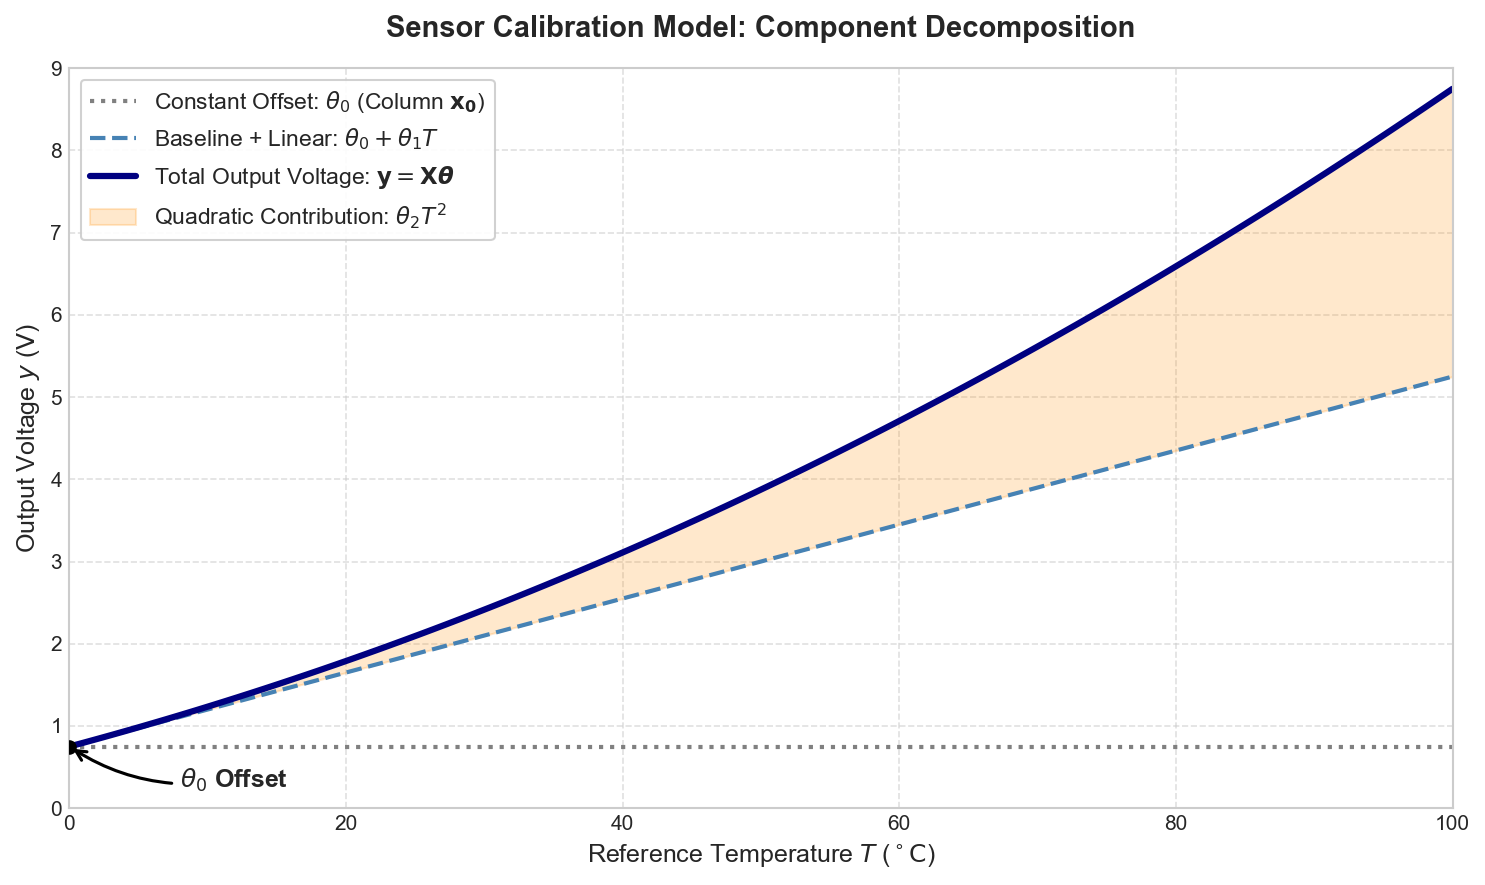

In [5]:
# Model parameters and reference temperature range
T = np.linspace(0, 100, 100) 
theta_0 = 0.75     # DC Offset (V)
theta_1 = 0.045    # Linear Sensitivity (V/°C)
theta_2 = 0.00035  # Quadratic Nonlinearity (V/°C^2)

# Compute individual model components (Xθ decomposition)
offset_comp = np.full_like(T, theta_0)
linear_comp = theta_1 * T
quad_comp = theta_2 * (T**2)
total_voltage = offset_comp + linear_comp + quad_comp

# Visualization
plot_component_decomposition(T, offset_comp, linear_comp, total_voltage, theta_0)

<div style="text-align: justify;">

As shown above, the total voltage output constitutes the superposition of the affine components ($\theta_0 + \theta_1 T$) and the quadratic nonlinearity ($\theta_2 T^2$). The accompanying animation dynamically visualizes the incremental construction of the characteristic curve.

</div>

In [6]:
# Render the animation video
render_and_display_scene(PolynomialCalibrationModel)

### 2. Estimation with Sensors of Varying Reliability
<div style="text-align: justify;">

*During data collection, different measuring instruments were used, resulting in independent measurement errors $n_i$ with different, known standard deviations $\sigma_i > 0$ for each observation $i$. Estimate the unknown parameter vector $\boldsymbol{\theta} = [\theta_0, \theta_1, \theta_2]^T$ so that more accurate measurements have a stronger influence on the fit than noisier ones. Your computational implementation must appropriately transform (scale) the data so as to avoid constructing $N \times N$ diagonal matrices in memory, returning both the estimated parameter vector and the optimal value of the weighted error criterion.*

</div>

<div style="text-align: justify;">

Ordinary least squares (OLS) treats every residual equally, minimizing the sum $J(\boldsymbol{\theta}) = \sum_{i=1}^N r_i^2$. This is appropriate when all measurements have comparable reliability. However, in our experimental setup, measurement quality varies considerably—different instruments yield errors with different known variances ($\sigma_i^2$). If we used standard OLS, an uncertain measurement would be treated exactly like every other measurement, influencing the estimation criterion just as much as a highly precise one. To address this, we introduce **Weighted Least Squares** (WLS). Each observation is weighted inversely to its **variance**:
$$w_i = \frac{1}{\sigma_i^2}$$
The modified cost criterion becomes:
$$J_W = \sum_{i=1}^N \frac{r_i^2}{\sigma_i^2}$$
In this way, a residual of a given magnitude is penalized strongly when it occurs in a precise measurement (small $\sigma_i$). The same residual is penalized weakly when it occurs in an uncertain measurement (large $\sigma_i$). Consequently, the fit is influenced primarily by the reliable measurements, while the uncertain observations contribute less strongly to the estimation of the parameter vector $\theta$.
By defining the whitened design matrix $\tilde{\mathbf{X}} = \mathbf{W}^{1/2}\mathbf{X}$ and whitened observation vector $\tilde{\mathbf{y}} = \mathbf{W}^{1/2}\mathbf{y}$—computed computationally via element-wise row scaling $\tilde{\mathbf{X}}_{i} = \mathbf{X}_{i}/\sigma_i$ and $\tilde{y}_i = y_i/\sigma_i$ to avoid $N \times N$ matrices in memory—the WLS objective reduces to standard OLS on the transformed data: $J_W(\boldsymbol{\theta}) = \Vert{}\tilde{\mathbf{y}} - \tilde{\mathbf{X}}\boldsymbol{\theta}\Vert{}_2^2$.

</div>

Scenario                         | rank | cond(X_w)  | cond(Normal) | ||X.T W r|| | J_opt    | Err OLS  | Err WLS 
----------------------------------------------------------------------------------------------------------------
Case 1: Homoscedastic Regime     | 3    | 1.20e+04   | 1.45e+08     | 7.19e-08    | 4.5897   | 0.0305   | 0.0305  
Case 2: Localized Noisy Outlier  | 3    | 1.19e+04   | 1.42e+08     | 1.41e-07    | 7.3390   | 0.3860   | 0.0316  
Case 3: Only 2 Precise Sensors   | 3    | 5.37e+06   | 2.88e+13     | 8.79e-08    | 0.0149   | 2.0940   | 0.5193  


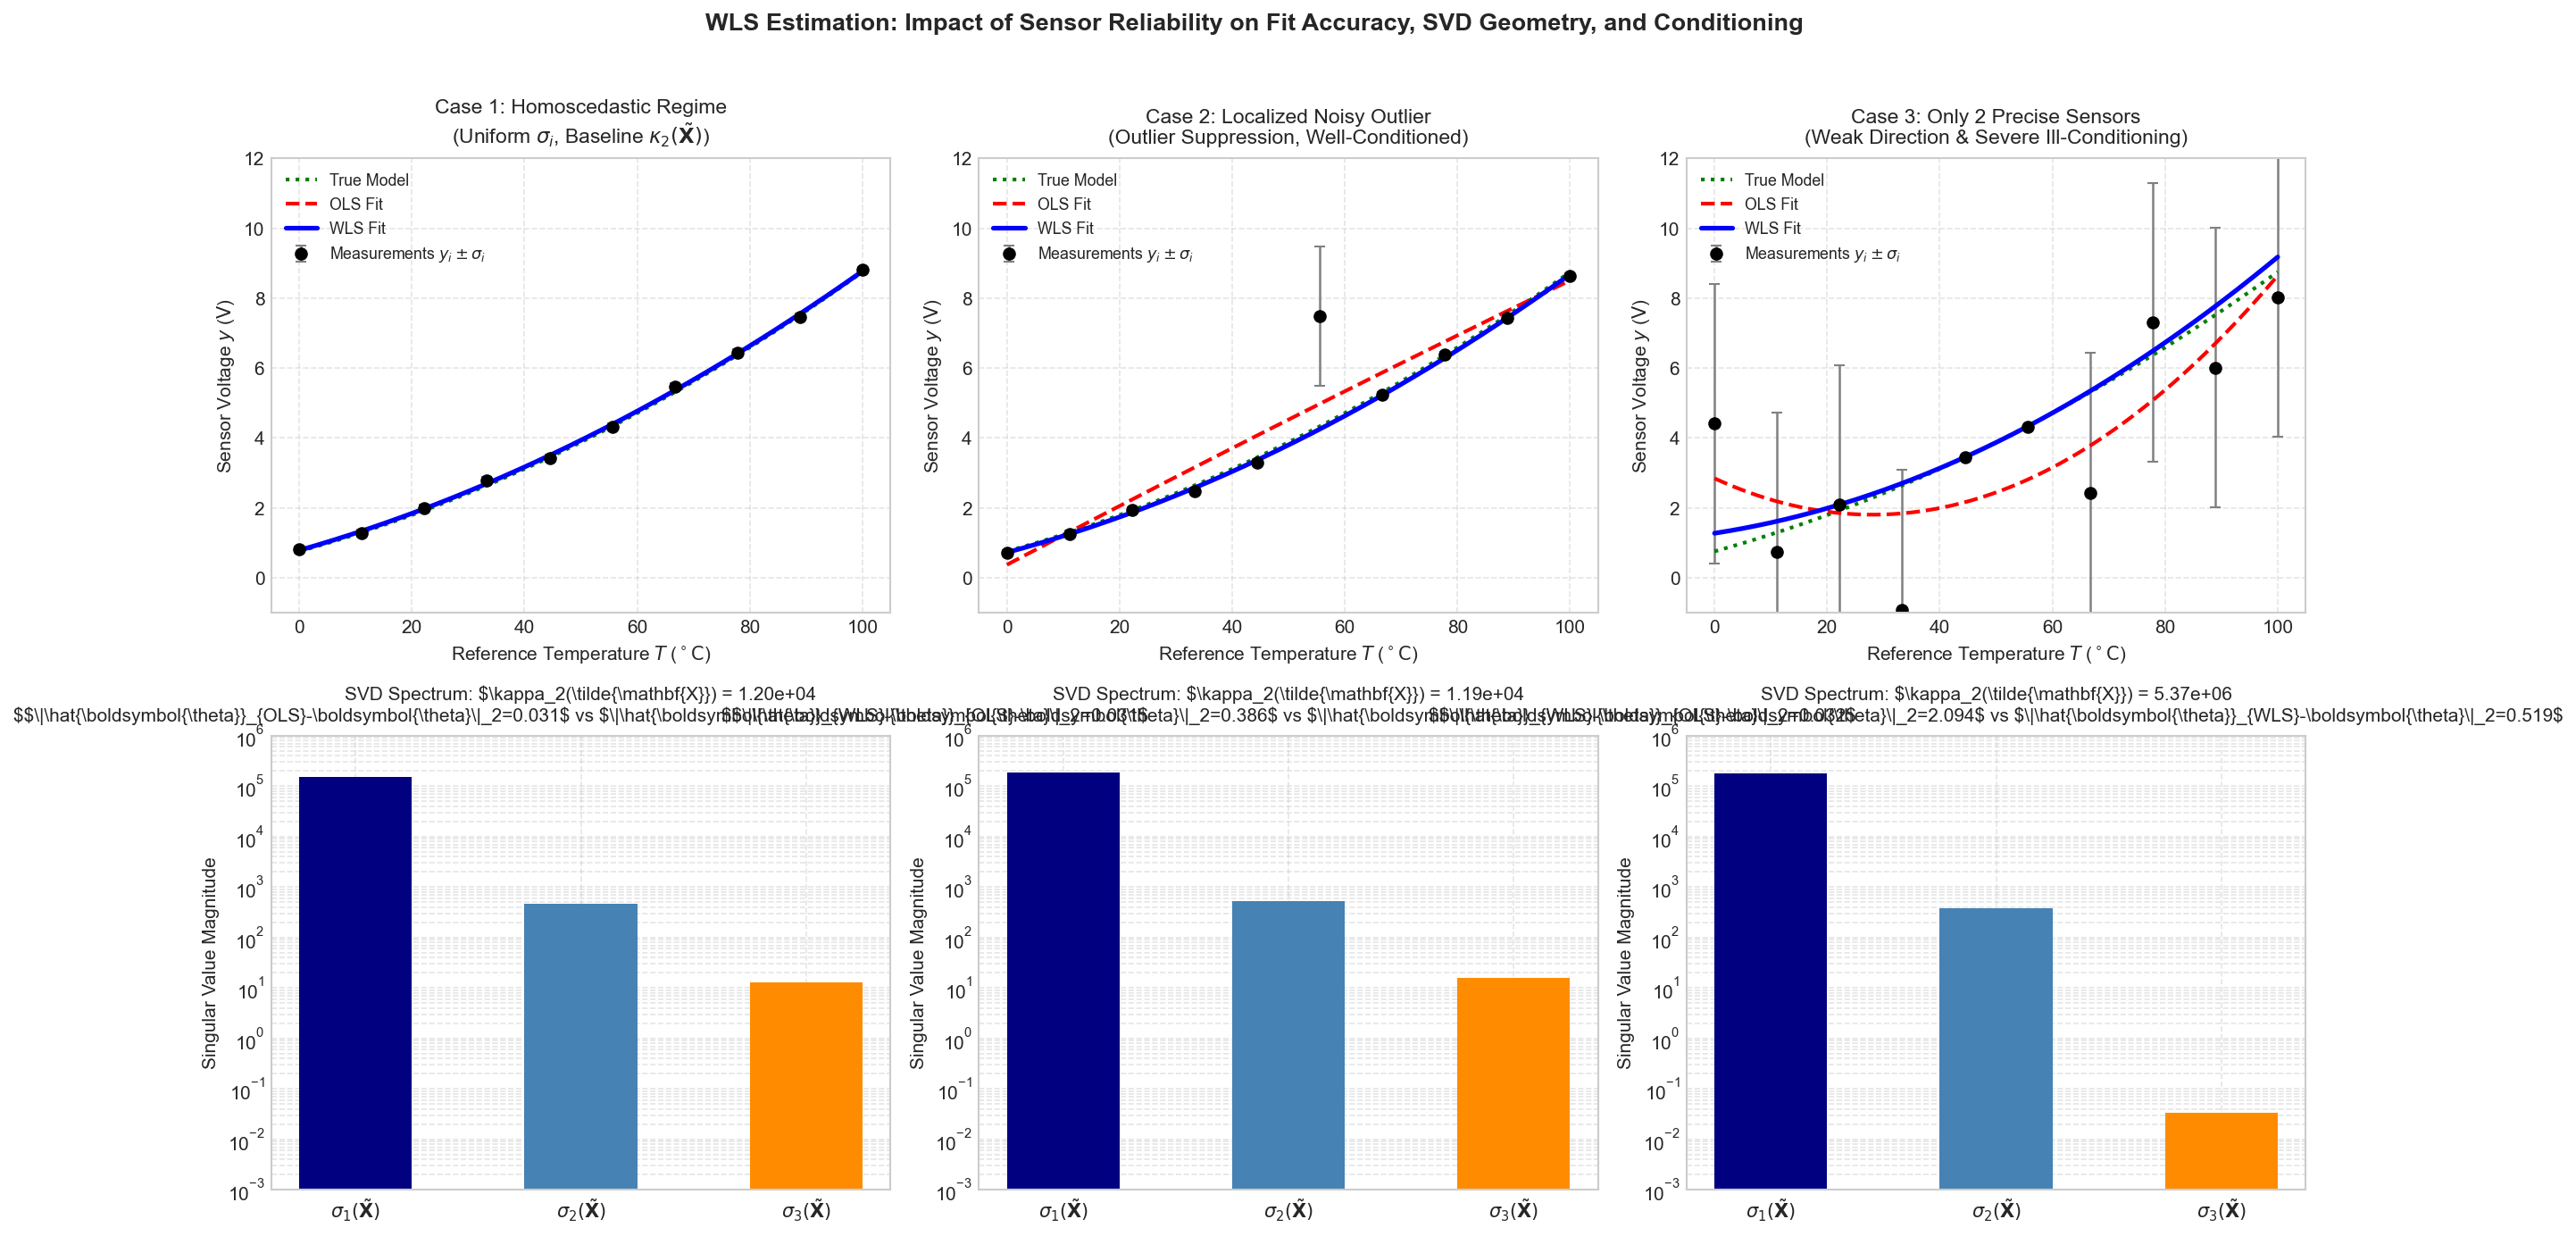

In [7]:
# Ensure reproducibility
np.random.seed(42)

# Experimental setup over [0, 100] °C and ground-truth parameters
T = np.linspace(0.0, 100.0, 10)
X = np.column_stack((np.ones_like(T), T, T**2))
theta_true = np.array([0.75, 0.045, 0.00035])
y_clean = X @ theta_true

# Dense temperature grid for plotting continuous calibration curves
T_dense = np.linspace(0.0, 100.0, 200)
X_dense = np.column_stack((np.ones_like(T_dense), T_dense, T_dense**2))
y_true_dense = X_dense @ theta_true

# -------------------------------------------------------------------------
# Define 3 Theoretical & Numerical Scenarios
# -------------------------------------------------------------------------

# Scenario 1: Homoscedastic Regime (Uniform variance -> WLS == OLS)
sigma_1 = np.full_like(T, 0.1)
y_1 = y_clean + np.random.normal(0.0, sigma_1)

# Scenario 2: Localized Noisy Outlier (Robustness of WLS)
sigma_2 = np.full_like(T, 0.08)
sigma_2[5] = 2.0  # Instrument at index 5 is highly unreliable
y_2 = y_clean + np.random.normal(0.0, 0.08, size=T.shape)
y_2[5] += 3.2     # Large measurement corruption at index 5

# Scenario 3: Sparse Precision / Effective Ill-Conditioning 
# Only 2 sensors (indices 4, 5) are precise; the other 8 have massive variance
sigma_3 = np.full_like(T, 50.0)
sigma_3[4:6] = 0.02
noise_3 = np.random.normal(0.0, 2.5, size=T.shape)
noise_3[4:6] = np.array([0.005, -0.005])
y_3 = y_clean + noise_3

scenarios = [
    ("Case 1: Homoscedastic Regime\n(Uniform $\\sigma_i$, Baseline $\\kappa_2(\\tilde{\\mathbf{X}})$)", y_1, sigma_1),
    ("Case 2: Localized Noisy Outlier\n(Outlier Suppression, Well-Conditioned)", y_2, sigma_2),
    ("Case 3: Only 2 Precise Sensors\n(Weak Direction & Severe Ill-Conditioning)", y_3, sigma_3)
]

# Generate the 2x3 diagnostic plot grid
plot_wls_diagnostics(scenarios, T, X, theta_true, T_dense, X_dense, y_true_dense, solve_wls)

<div style="text-align: justify;">

The diagnostic plots compare Ordinary Least Squares (OLS) and Weighted Least Squares (WLS) across three distinct measurement scenarios, designed to illustrate the robustness and geometric properties of WLS estimation.   
In the first scenario—characterized by homoscedastic noise where all sensors share identical reliability—both methods yield identical parameter fits and a well-conditioned singular value spectrum.   
The second scenario introduces a localized outlier with massive uncertainty. While OLS is heavily skewed by this erroneous data point, WLS successfully suppresses its influence by assigning it a near-zero weight, thereby preserving the integrity of the underlying physical model.   
The final scenario illustrates a regime of sparse precision, where only two sensors remain precise amidst highly uncertain data. Although WLS correctly anchors the fit to the reliable measurements, this severe lack of independent information collapses the third singular value and triggers a high condition number, exposing the inherent ill-conditioning of the experimental setup.

</div>

In [8]:
# Render the 3D animation video
render_and_display_scene(WhiteningGeometry)

<div style="text-align: justify;">

Complementing these static insights, the animation visualizes the geometric mechanism of the whitening transformation that underpins weighted least squares. Initially, when viewed in standard Euclidean space, the weighted residual vector appears non-orthogonal to the model column space, creating a geometric paradox. However, as the coordinate system undergoes the linear scaling transformation dictated by the square root of the precision weights, the entire space stretches and compresses relative to each sensor's reliability. In this newly transformed coordinate frame, the residual vector becomes perfectly orthogonal to the whitened model space, geometrically proving that weighted least squares is simply an ordinary orthogonal projection executed within a properly rescaled universe.

</div>

### 3. Stabilization over a Narrow Temperature Window

<div style="text-align: justify;">

*In a second experimental trial, all reference temperatures $T_i$ were chosen very close to one another (e.g., between $25.0^\circ\text{C}$ and $25.2^\circ\text{C}$). Explain qualitatively and quantitatively why the standard parameter estimate becomes highly sensitive to measurement noise in this setup, even though the fitted voltage curve appears visually accurate. Next, modify the optimization criterion by introducing a trade-off parameter $\lambda > 0$ that penalizes the magnitude of the coefficients $\theta_1$ and $\theta_2$, while leaving the constant offset $\theta_0$ completely unpenalized. Compute the stabilized solution by formulating a single augmented linear least-squares system, thereby avoiding the explicit multiplication of the design matrix by its transpose.*

</div>

<div style="text-align: justify;">

**Qualitative Explanation**:
When all reference temperatures $T_i$ are restricted to a very narrow interval, such as between $25.0^\circ\text{C}$ and $25.2^\circ\text{C}$, the design matrix $X$ for the second-order polynomial model $y = \theta_0 + \theta_1 T + \theta_2 T^2$ becomes severely **ill-conditioned**. Qualitatively, over such a localized region, the quadratic term $T^2$ exhibits nearly perfect linear dependence on the linear term $T$ and the constant column $\mathbf{1}$. This inherent collinearity leads the optimization algorithm to assign massive positive and negative values to the coefficients $\theta_1$ and $\theta_2$ that cancel each other out within the interval $[25.0, 25.2]$, creating an artificially steep local curvature. As a result, even the slightest measurement noise in the observation vector $y$ induces massive and unstable fluctuations in the parameter estimates $\theta$, despite the fact that the fitted trend curve appears visually smooth and accurate strictly within this $0.2^\circ\text{C}$ window.

**Quantitative Explanation**:
Quantitatively, if we center the temperature around its mean $\bar{T} = 25.1$ by defining $\Delta T_i = T_i - \bar{T}$, where $\Delta T_i \in [-0.1, 0.1]$, the quadratic term can be approximated via Taylor expansion as $T_i^2 = (\bar{T} + \Delta T_i)^2 \approx \bar{T}^2 + 2\bar{T}\Delta T_i + (\Delta T_i)^2$. Given that $\Delta T_i$ is on the order of $10^{-1}$, the term $(\Delta T_i)^2$ is on the order of $10^{-2}$ and becomes negligible compared to the linear term, rendering the columns of the design matrix **nearly linearly dependent**. The condition number of the matrix, defined as the ratio $\kappa_2(X) = \sigma_{\max}/\sigma_{\min}$, skyrockets from moderate values to levels on the order of $10^7$ or higher. Since the variance of the estimated parameters scales with the square of the condition number ($\kappa_2^2$) when solving via normal equations, measurement noise is dramatically amplified, rendering the standard estimate extremely unstable.

</div>

<div style="text-align: justify;">

To stabilize the estimation without penalizing the constant offset $\theta_0$, we introduce **Tikhonov regularization** (Ridge regression) specifically penalizing $\theta_1$ and $\theta_2$ with a trade-off parameter $\lambda > 0$. By defining the selective penalty matrix $\mathbf{L} = \text{diag}(0, 1, 1)$, the modified optimization criterion is expressed as:
$$J_\lambda(\boldsymbol{\theta}) = \|\mathbf{y} - \mathbf{X}\boldsymbol{\theta}\|_2^2 + \lambda(\theta_1^2 + \theta_2^2) = \|\mathbf{y} - \mathbf{X}\boldsymbol{\theta}\|_2^2 + \lambda \|\mathbf{L}\boldsymbol{\theta}\|_2^2$$
To avoid explicitly forming the normal equations matrix $\mathbf{X}^T\mathbf{X}$—which squares the condition number $\kappa_2(\mathbf{X}^T\mathbf{X}) = \kappa_2(\mathbf{X})^2$ and induces severe numerical instability—we reformulate the objective as a **single augmented linear least-squares system** $\min_{\boldsymbol{\theta}} \|\tilde{\mathbf{y}}_{\text{aug}} - \tilde{\mathbf{X}}_{\text{aug}}\boldsymbol{\theta}\|_2^2$:
$$\tilde{\mathbf{X}}_{\text{aug}} = \begin{bmatrix} \mathbf{X} \\ \sqrt{\lambda}\mathbf{L} \end{bmatrix} \in \mathbb{R}^{(N+3) \times 3}, \quad \tilde{\mathbf{y}}_{\text{aug}} = \begin{bmatrix} \mathbf{y} \\ \mathbf{0}_{3 \times 1} \end{bmatrix} \in \mathbb{R}^{(N+3) \times 1}$$
This augmented system is solved directly on $\tilde{\mathbf{X}}_{\text{aug}}$ using numerically stable **orthogonal matrix factorizations** (QR or SVD).

</div>

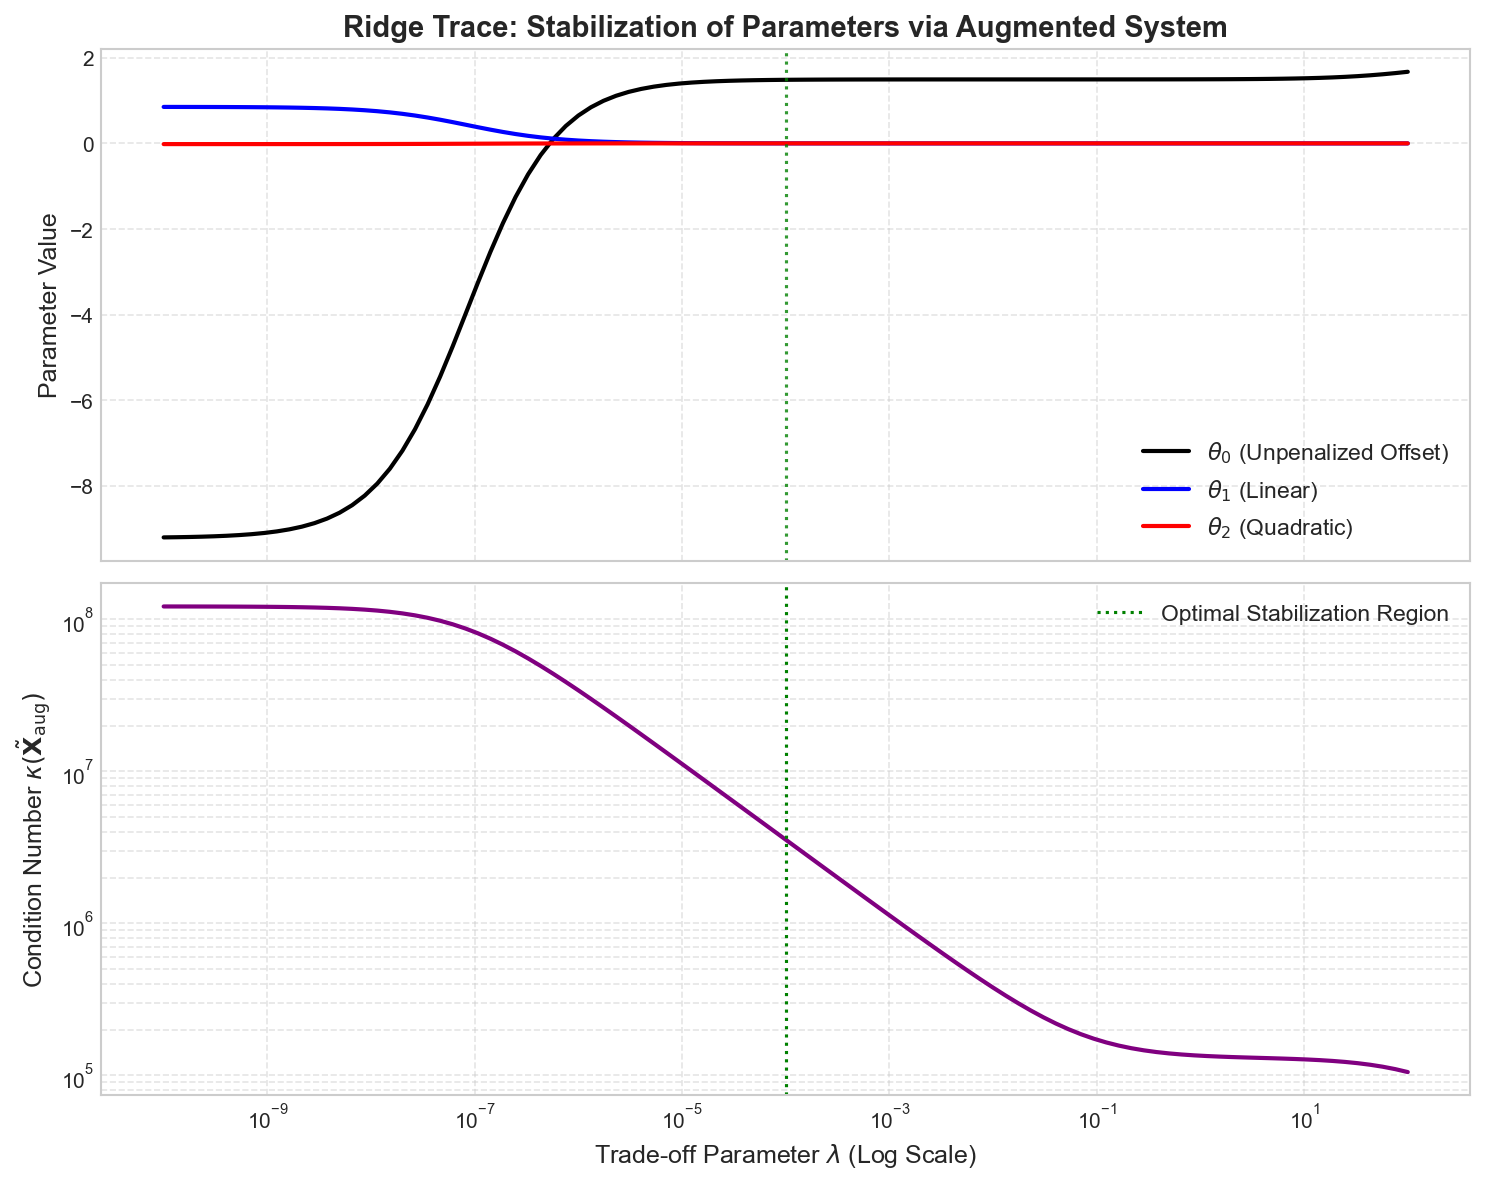

In [9]:
# 1. Generate ill-conditioned data (narrow window)
T_ill = np.linspace(25.0, 25.2, 20)
X_ill = np.column_stack([np.ones_like(T_ill), T_ill, T_ill**2])

theta_true_ill = np.array([1.0, 0.03, 0.0004])
y_true_ill = X_ill @ theta_true_ill

np.random.seed(42)
y_noisy_ill = y_true_ill + np.random.normal(0, 0.001, size=T_ill.shape)

# 2. Penalty Matrix & Lambda range
L = np.diag([0, 1, 1])  # Penalize theta_1, theta_2, leave theta_0
lams = np.logspace(-10, 2, 100)

# 3. Execution & Visualization (The Call)
# Περνάμε τη συνάρτηση solve_tikhonov_augmented απευθείας στο plot function
plot_ridge_trace(X_ill, y_noisy_ill, L, lams, solve_tikhonov_augmented)

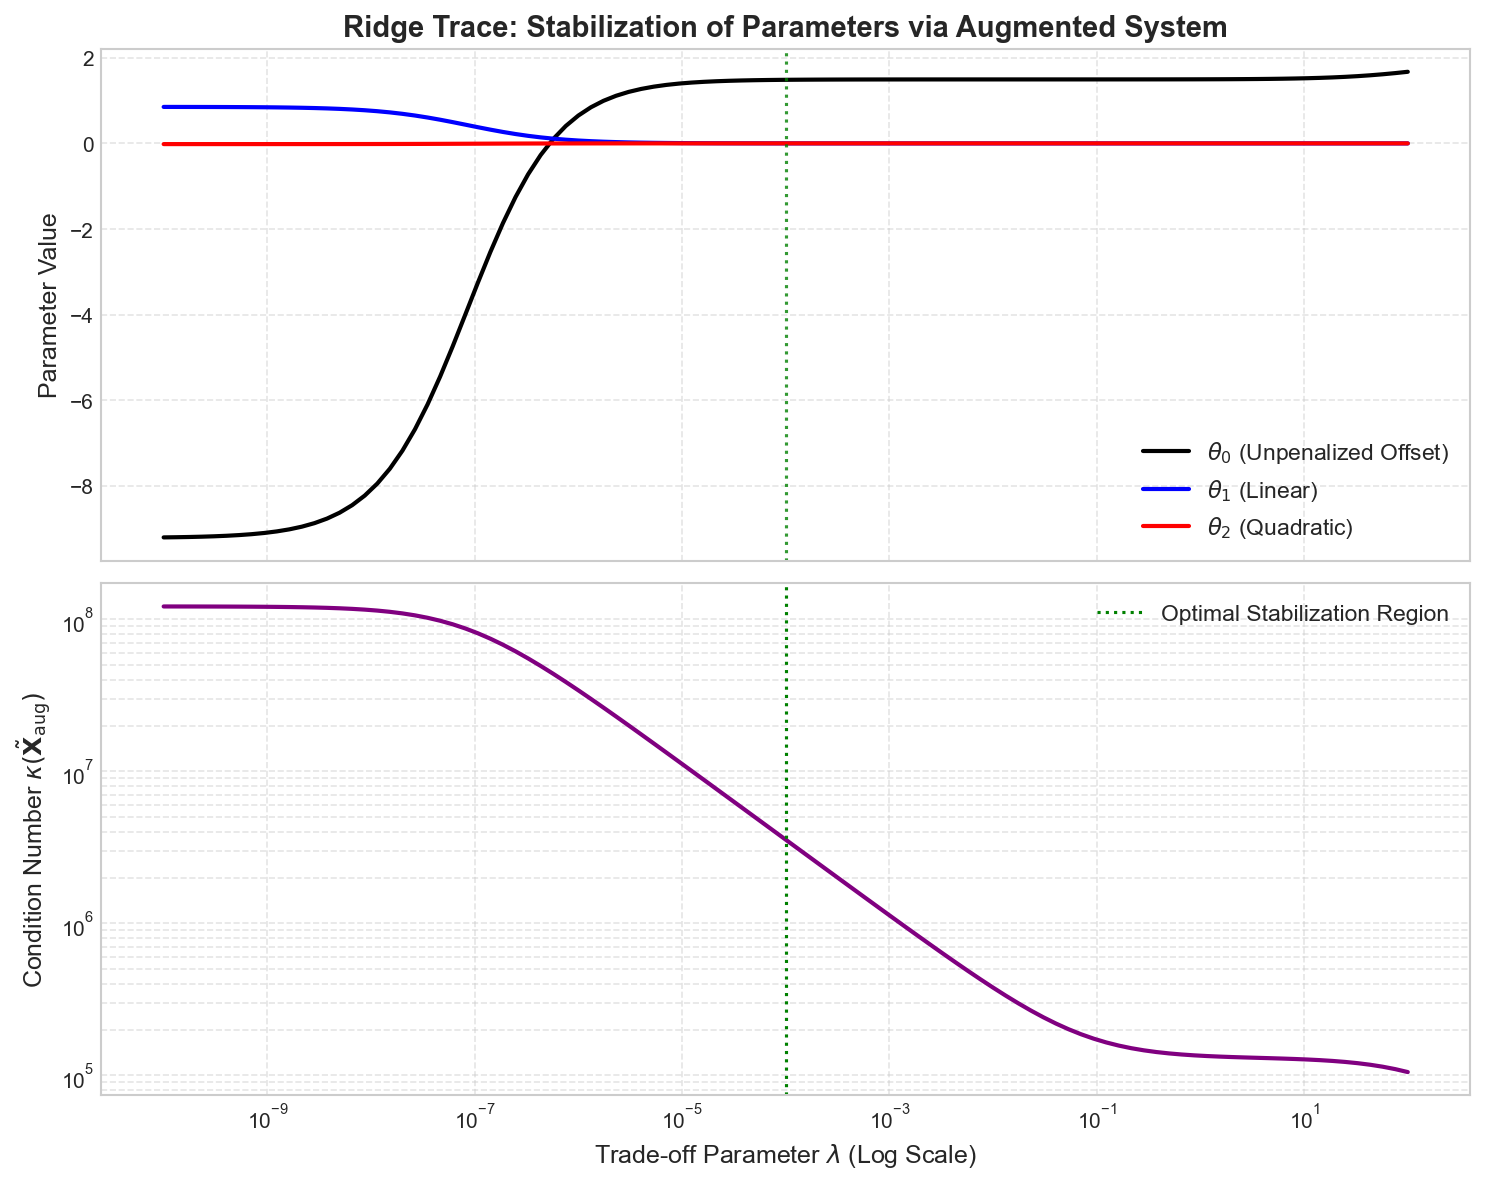

In [10]:
# 1. Generate ill-conditioned data (narrow window)
T = np.linspace(25.0, 25.2, 20)
X = np.column_stack([np.ones_like(T), T, T**2])

# 2. True baseline parameters
theta_true = np.array([1.0, 0.03, 0.0004])
y_true = X @ theta_true

# 3. Add tiny measurement noise (this destroys standard OLS)
np.random.seed(42)
y_noisy = y_true + np.random.normal(0, 0.001, size=T.shape)

# 4. Penalty Matrix L (Penalize theta_1, theta_2, but leave theta_0 unpenalized)
L = np.diag([0, 1, 1])

# 5. Define lambda range
lams = np.logspace(-10, 2, 100)

# 6. Generate the Ridge Trace and Condition Number plots
plot_ridge_trace(X, y_noisy, L, lams, solve_tikhonov_augmented)

<div style="text-align: justify;">

The provided plot demonstrates how the augmented linear system stabilizes parameter estimation when dealing with highly collinear data from a narrow temperature window. In the standard Ordinary Least Squares approach, which corresponds to a near-zero penalty parameter, the condition number of the system is **extremely high**. This ill-conditioning causes the model's parameters to **explode** in opposite directions just to fit the local noise. By introducing a targeted regularization penalty, we systematically shrink the linear and quadratic coefficients while leaving the constant offset unpenalized. As the penalty parameter increases to the optimal region around $10^{-4}$, the condition number drops significantly, and all parameters safely converge to stable, realistic values, proving the quantitative success of the regularization.

</div>

In [11]:
# 1. Render the extrapolation illusion animation video
render_and_display_scene(ExtrapolationIllusion)

<div style="text-align: justify;">

This animation illustrates the dangerous illusion of a visually accurate fit in ill-conditioned regression problems. Within the narrow experimental window of 25.0 to 25.2 degrees Celsius, both the standard OLS and the stabilized augmented model seamlessly overlap and capture the data points perfectly. However, this local accuracy is highly deceptive. When we zoom out to observe a broader temperature range, the standard OLS model diverges dramatically, forming a wild and unphysical curve due to its extreme sensitivity to minor measurement noise. In stark contrast, the stabilized curve computed via the augmented system completely resists this noise amplification, maintaining a robust and physically realistic trajectory well beyond the boundaries of the original measurement window.

</div>